# Predictive Modelling with Machine Learning
## Wisconsin Breast Cancer Diagnostic Dataset

**Course:** R1PHR26901 – Mathematical Foundations and Advanced Machine Learning  
**Practical:** Develop predictive models using Python and compare at least four algorithms on a real-world dataset.

### Aim
Build and evaluate classification models that predict whether a breast tumour sample is **benign** or **malignant** using the Wisconsin Breast Cancer Diagnostic dataset.

### Algorithms
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Support Vector Machine (RBF kernel)
5. XGBoost

### Experimental design
- Load the dataset from scikit-learn.
- Inspect data quality, class balance and feature distributions.
- Use a stratified 80:20 train/test split.
- Fit preprocessing only on the training data through scikit-learn pipelines.
- Use cross-validation on the training set for model comparison.
- Evaluate the final fitted models once on the held-out test set.
- Compare Accuracy, Precision, Recall, F1-score, ROC-AUC and execution time.
- Visualize confusion matrices, ROC curves and feature importance.

> **Important:** This is an educational machine-learning experiment, not a clinical diagnostic system. The dataset is small and historical; model performance here must not be interpreted as evidence of clinical readiness.

## 1. Imports and reproducibility

We use a fixed random seed so that the train/test split and stochastic models are reproducible. If XGBoost is not installed, install the packages listed in `requirements.txt`.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from xgboost import XGBClassifier

RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Python: 3.13.15
NumPy: 2.5.3
Pandas: 3.1.0


## 2. Load the dataset

The scikit-learn Wisconsin Breast Cancer dataset contains 569 observations and 30 numeric features. Its target labels are encoded as:

- `0` = malignant
- `1` = benign

For easier interpretation, we will convert the target to a human-readable series while preserving this mapping.

In [2]:
dataset = load_breast_cancer(as_frame=True)

X = dataset.data.copy()
y = dataset.target.copy()

target_names = {0: "malignant", 1: "benign"}
y_named = y.map(target_names)

df = X.copy()
df["diagnosis"] = y_named

print("Dataset shape:", df.shape)
print("Number of features:", X.shape[1])
print("\\nTarget mapping:", target_names)
display(df.head())

Dataset shape: (569, 31)
Number of features: 30
\nTarget mapping: {0: 'malignant', 1: 'benign'}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


## 3. Initial data inspection

In [3]:
print("Data types:")
display(X.dtypes.value_counts().rename("number_of_columns").to_frame())

print("\\nMissing values (top 10):")
display(X.isna().sum().sort_values(ascending=False).head(10).to_frame("missing_values"))

print("\\nDescriptive statistics:")
display(X.describe().T.round(2))

print("\\nClass distribution:")
class_counts = y_named.value_counts().reindex(["benign", "malignant"])
display(class_counts.rename("count").to_frame())
print("Class proportions:")
display((class_counts / len(y_named) * 100).round(2).rename("percentage").to_frame())

Data types:


,number_of_columns
float64,30


\nMissing values (top 10):


,missing_values
mean radius,0
mean texture,0
worst symmetry,0
worst concave points,0
worst concavity,0
worst compactness,0
worst smoothness,0
worst area,0
worst perimeter,0
worst texture,0


\nDescriptive statistics:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.13,3.52,6.98,11.70,13.37,15.78,28.11
mean texture,569.0,19.29,4.30,9.71,16.17,18.84,21.80,39.28
mean perimeter,569.0,91.97,24.30,43.79,75.17,86.24,104.10,188.50
mean area,569.0,654.89,351.91,143.50,420.30,551.10,782.70,2501.00
mean smoothness,569.0,0.10,0.01,0.05,0.09,0.10,0.11,0.16
mean compactness,569.0,0.10,0.05,0.02,0.06,0.09,0.13,0.35
mean concavity,569.0,0.09,0.08,0.00,0.03,0.06,0.13,0.43
mean concave points,569.0,0.05,0.04,0.00,0.02,0.03,0.07,0.20
mean symmetry,569.0,0.18,0.03,0.11,0.16,0.18,0.20,0.30
mean fractal dimension,569.0,0.06,0.01,0.05,0.06,0.06,0.07,0.10


\nClass distribution:


,count
target,
benign,357
malignant,212


Class proportions:


,percentage
target,
benign,62.74
malignant,37.26


## 4. Exploratory data analysis

### 4.1 Class distribution

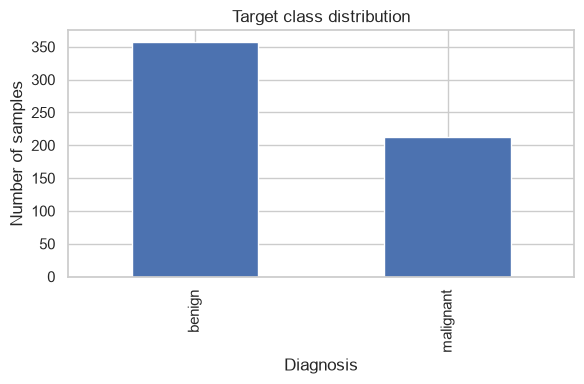

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
y_named.value_counts().reindex(["benign", "malignant"]).plot(kind="bar", ax=ax)
ax.set(title="Target class distribution", xlabel="Diagnosis", ylabel="Number of samples")
plt.tight_layout()
plt.show()

### 4.2 Feature distributions

The following plot shows a sample of features from the dataset. It is intended for exploratory inspection, not feature selection.

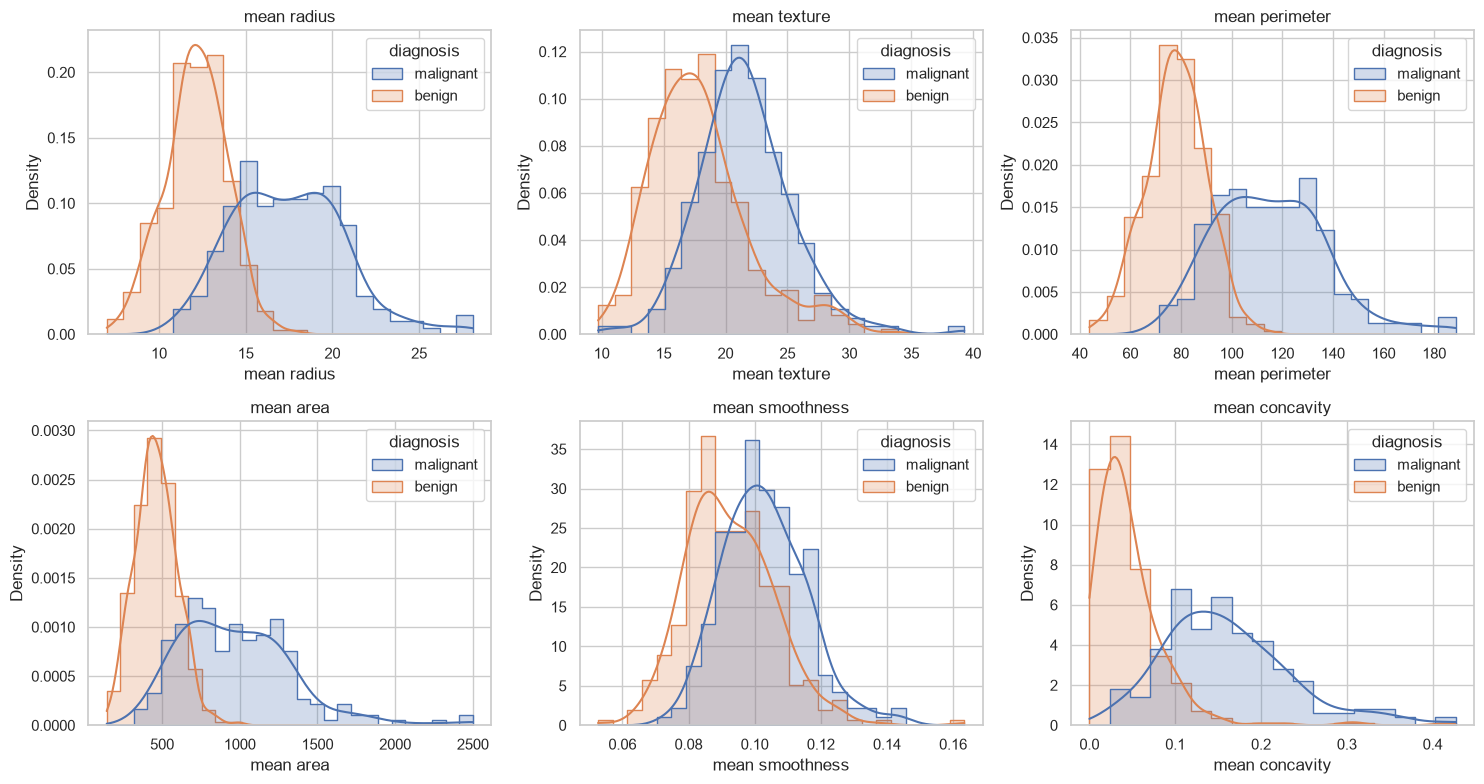

In [5]:
sample_features = [
    "mean radius", "mean texture", "mean perimeter",
    "mean area", "mean smoothness", "mean concavity"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for feature, ax in zip(sample_features, axes.ravel()):
    sns.histplot(data=df, x=feature, hue="diagnosis", kde=True,
                 element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(feature)
plt.tight_layout()
plt.show()

### 4.3 Correlation among selected features

Many measurements are correlated. This is useful context when interpreting coefficients and feature importance.

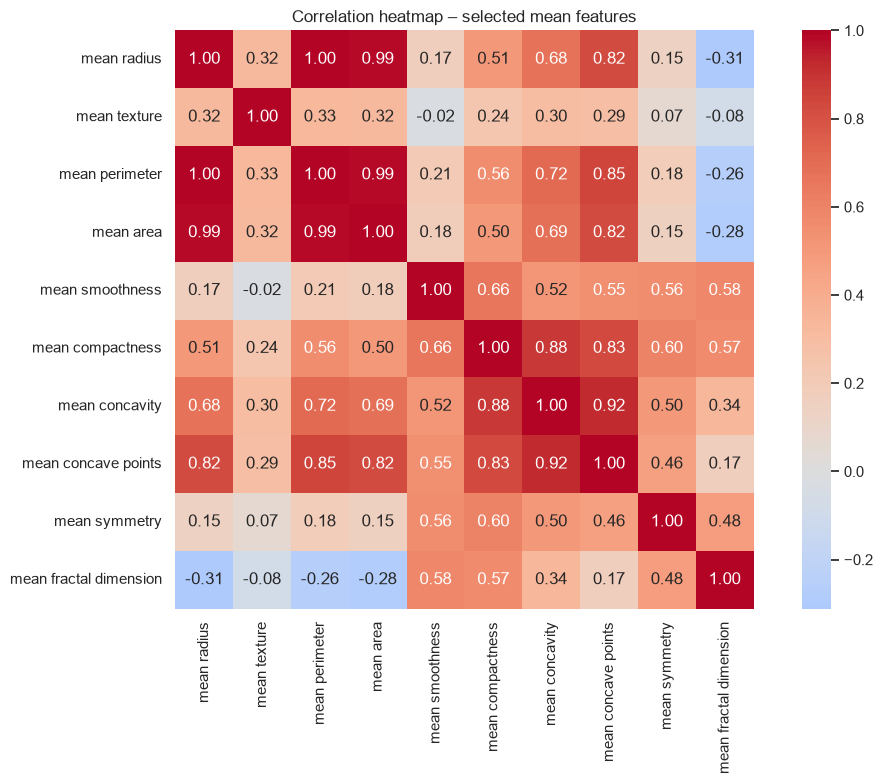

In [6]:
corr_features = [
    "mean radius", "mean texture", "mean perimeter", "mean area",
    "mean smoothness", "mean compactness", "mean concavity",
    "mean concave points", "mean symmetry", "mean fractal dimension"
]
plt.figure(figsize=(11, 8))
sns.heatmap(X[corr_features].corr(), cmap="coolwarm", center=0, annot=True,
            fmt=".2f", square=True)
plt.title("Correlation heatmap – selected mean features")
plt.tight_layout()
plt.show()

## 5. Train/test split

We reserve 20% of the data as a final hold-out test set. Stratification preserves approximately the same class proportions in both subsets. The test set will not be used for fitting or model selection.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("\\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename(index=target_names).to_frame("proportion"))
print("Test class proportions:")
display(y_test.value_counts(normalize=True).sort_index().rename(index=target_names).to_frame("proportion"))

Training set: (455, 30)
Test set: (114, 30)
\nTraining class proportions:


,proportion
target,
malignant,0.373626
benign,0.626374


Test class proportions:


,proportion
target,
malignant,0.368421
benign,0.631579


## 6. Define models and preprocessing

Scaling is important for Logistic Regression and SVM because they are sensitive to feature magnitudes. Decision Tree, Random Forest and XGBoost do not require standardization.

Imputation is included in every pipeline to make the workflow robust if missing values occur in future datasets. The imputer and scaler are fitted only on the relevant training fold, avoiding preprocessing leakage.

In [8]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            random_state=RANDOM_STATE, class_weight="balanced"
        ))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300, random_state=RANDOM_STATE,
            class_weight="balanced", n_jobs=-1
        ))
    ]),
    "SVM (RBF)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf", probability=True, class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),
    "XGBoost": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", XGBClassifier(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}

print("Models defined:", list(models.keys()))

Models defined: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'SVM (RBF)', 'XGBoost']


## 7. Cross-validation on the training set

We use stratified 5-fold cross-validation and report mean and standard deviation for Accuracy, F1 and ROC-AUC. This gives a more stable training-stage comparison than relying on one split alone.

The held-out test set remains untouched until the next section.

In [9]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_rows = []
for name, estimator in models.items():
    scores = cross_validate(
        estimator, X_train, y_train,
        cv=cv, scoring=scoring, n_jobs=-1,
        return_train_score=False
    )
    row = {"Model": name}
    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[f"{metric.upper()} mean"] = values.mean()
        row[f"{metric.upper()} std"] = values.std()
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).set_index("Model").sort_values("ROC_AUC mean", ascending=False)
display(cv_results.round(4))

,ACCURACY mean,ACCURACY std,PRECISION mean,PRECISION std,RECALL mean,RECALL std,F1 mean,F1 std,ROC_AUC mean,ROC_AUC std
Model,,,,,,,,,,
SVM (RBF),0.9736,0.0112,0.9825,0.0109,0.9754,0.0179,0.9788,0.0091,0.9963,0.0036
Logistic Regression,0.9780,0.0098,0.9795,0.0162,0.9860,0.0131,0.9825,0.0078,0.9959,0.0050
XGBoost,0.9670,0.0155,0.9757,0.0174,0.9719,0.0211,0.9736,0.0125,0.9942,0.0045
Random Forest,0.9538,0.0146,0.9715,0.0086,0.9544,0.0211,0.9627,0.0120,0.9916,0.0053
Decision Tree,0.9319,0.0128,0.9361,0.0274,0.9579,0.0179,0.9464,0.0093,0.9231,0.0195


## 8. Fit models and evaluate on the held-out test set

We fit each complete pipeline on the training set, then predict the test set. Positive class `1` corresponds to **benign** in the original scikit-learn target encoding. The metric calculations below therefore treat benign as the positive class. We also print class-specific precision, recall and F1 in the classification reports so malignant-case performance can be inspected separately.

For healthcare-oriented interpretation, do not rely on accuracy alone. In particular, inspect malignant-class recall because a false negative means a malignant sample was predicted as benign.

In [10]:
fitted_models = {}
test_rows = []
prediction_times = {}

for name, estimator in models.items():
    start = time.perf_counter()
    estimator.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start

    start = time.perf_counter()
    y_pred = estimator.predict(X_test)
    predict_seconds = time.perf_counter() - start

    # Probability/score for class 1 (benign), used for ROC-AUC.
    if hasattr(estimator, "predict_proba"):
        y_score = estimator.predict_proba(X_test)[:, 1]
    else:
        y_score = estimator.decision_function(X_test)

    fitted_models[name] = estimator
    prediction_times[name] = (fit_seconds, predict_seconds)

    test_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (benign)": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Recall (benign)": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "F1 (benign)": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_score),
        "Fit time (s)": fit_seconds,
        "Predict time (s)": predict_seconds
    })

test_results = pd.DataFrame(test_rows).set_index("Model").sort_values("ROC-AUC", ascending=False)
display(test_results.round(4))

,Accuracy,Precision (benign),Recall (benign),F1 (benign),ROC-AUC,Fit time (s),Predict time (s)
Model,,,,,,,
Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954,0.0107,0.0008
XGBoost,0.9561,0.9467,0.9861,0.9660,0.9944,0.2206,0.0012
Random Forest,0.9386,0.9577,0.9444,0.9510,0.9940,0.1436,0.0148
SVM (RBF),0.9649,0.9857,0.9583,0.9718,0.9940,0.0077,0.0012
Decision Tree,0.9298,0.9571,0.9306,0.9437,0.9296,0.0069,0.0015


### 8.1 Class-specific classification reports

The classification report labels class `0` as malignant and class `1` as benign. Pay particular attention to recall for the malignant class.

In [11]:
for name, estimator in fitted_models.items():
    print("\\n" + "=" * 72)
    print(name)
    print("=" * 72)
    y_pred = estimator.predict(X_test)
    print(classification_report(
        y_test, y_pred,
        labels=[0, 1],
        target_names=["malignant", "benign"],
        zero_division=0
    ))

\n========================================================================
Logistic Regression
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

\n========================================================================
Decision Tree
              precision    recall  f1-score   support

   malignant       0.89      0.93      0.91        42
      benign       0.96      0.93      0.94        72

    accuracy                           0.93       114
   macro avg       0.92      0.93      0.93       114
weighted avg       0.93      0.93      0.93       114

\n========================================================================
Random Forest
              precision    recall  f1-score   support

   malignant      

## 9. Visual model comparison

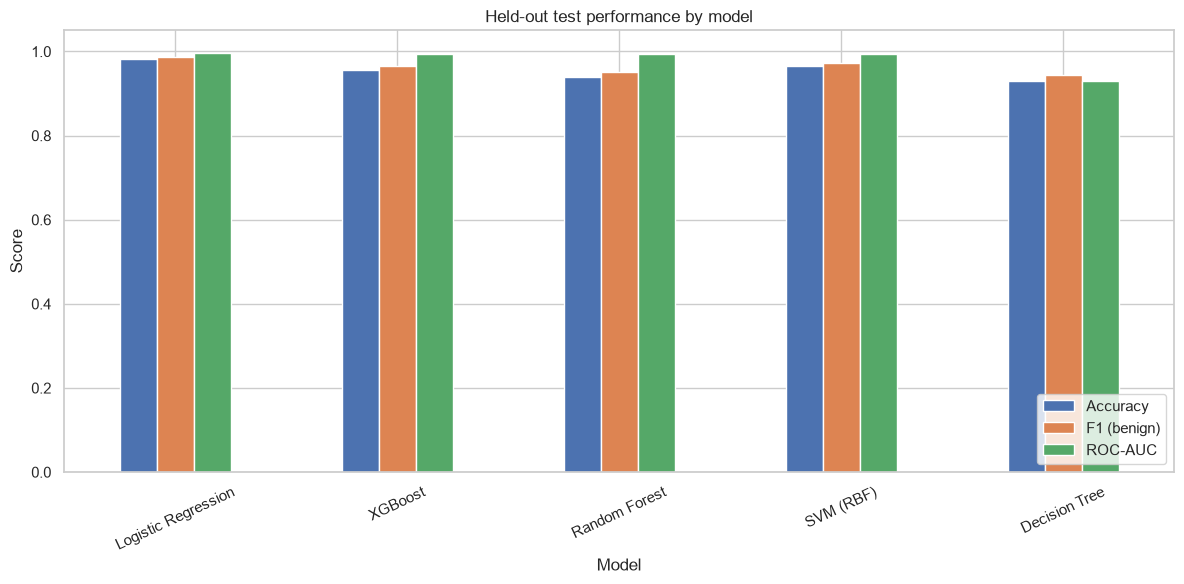

In [12]:
plot_metrics = ["Accuracy", "F1 (benign)", "ROC-AUC"]
ax = test_results[plot_metrics].plot(kind="bar", figsize=(12, 6), ylim=(0, 1.05))
ax.set_title("Held-out test performance by model")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.tick_params(axis="x", rotation=25)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 9.1 Confusion matrices

Rows represent actual classes and columns represent predicted classes. Class order is malignant, benign.

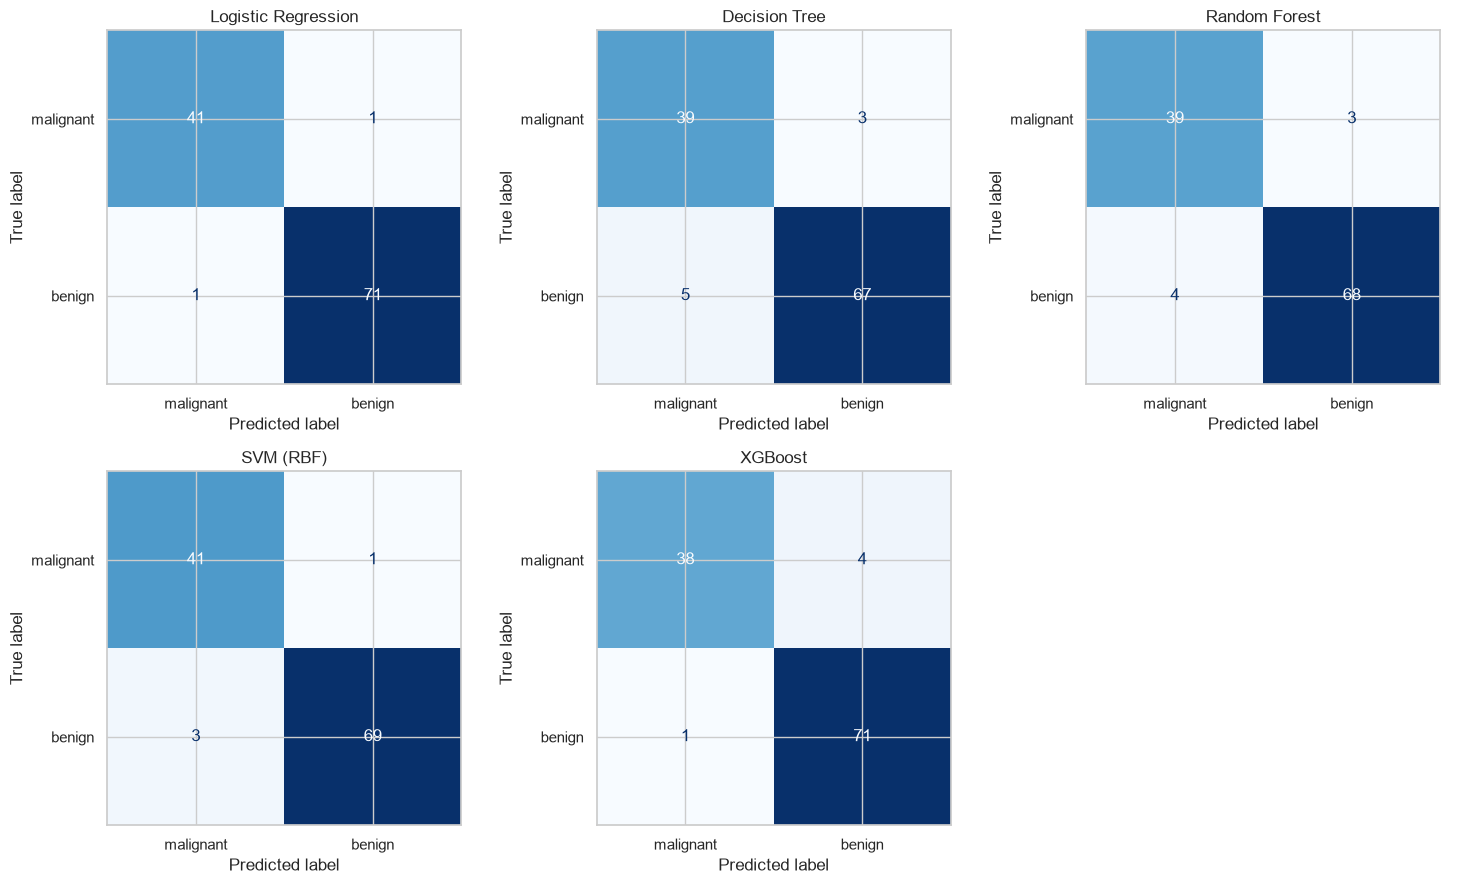

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, estimator) in zip(axes.ravel(), fitted_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        estimator, X_test, y_test,
        labels=[0, 1],
        display_labels=["malignant", "benign"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name)
for ax in axes.ravel()[len(fitted_models):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 9.2 ROC curves

The ROC curve here treats benign (class 1) as the positive class, consistent with the ROC-AUC calculation above. The classification reports provide the malignant-class recall separately.

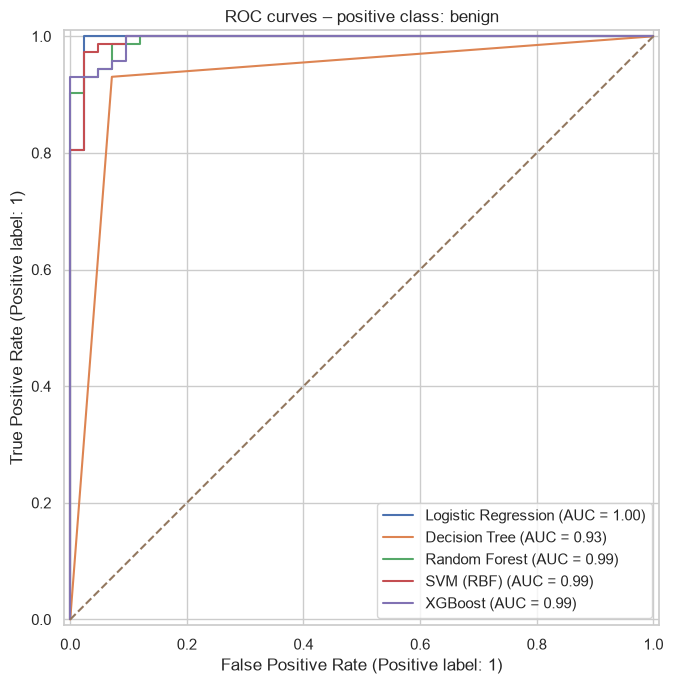

In [14]:
fig, ax = plt.subplots(figsize=(8, 7))
for name, estimator in fitted_models.items():
    RocCurveDisplay.from_estimator(
        estimator, X_test, y_test, pos_label=1, name=name, ax=ax
    )
ax.plot([0, 1], [0, 1], linestyle="--", label="Chance")
ax.set_title("ROC curves – positive class: benign")
plt.tight_layout()
plt.show()

## 10. Feature importance / model interpretation

Tree-based models expose impurity-based feature importance. These values describe how the fitted tree ensemble used features; they are not causal effects and can be biased toward certain feature types or correlated variables.

We show the top 15 features for Random Forest and XGBoost.

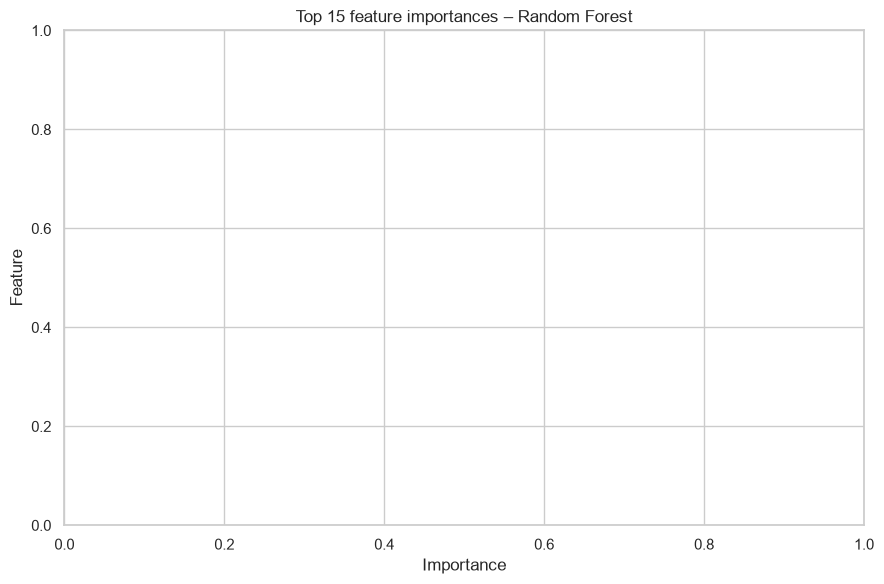

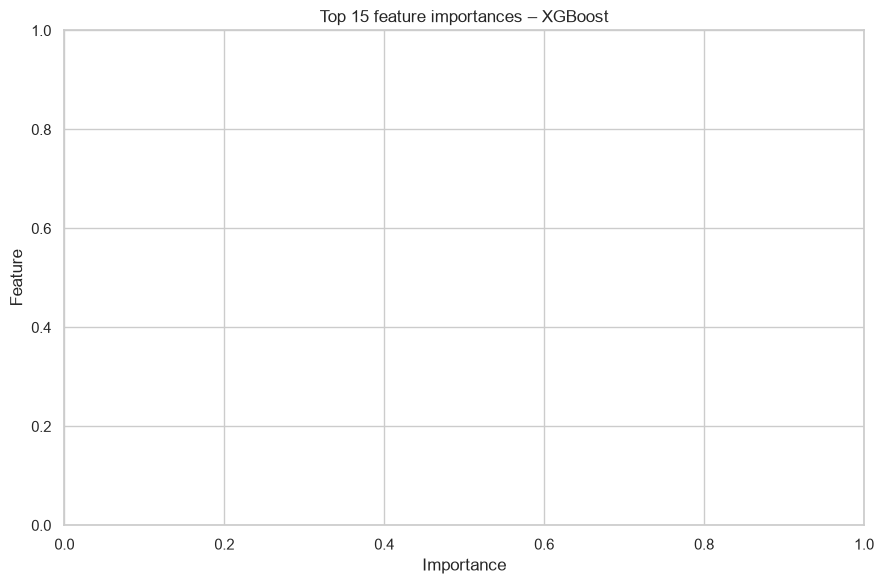

In [15]:
for model_name in ["Random Forest", "XGBoost"]:
    fitted_pipeline = fitted_models[model_name]
    fitted_estimator = fitted_pipeline.named_steps["model"]
    importances = pd.Series(
        fitted_estimator.feature_importances_,
        index=X.columns
    ).sort_values(ascending=False).head(15)

    plt.figure(figsize=(9, 6))
    ax.barh(importances.index[::-1], importances.values[::-1])
    plt.title(f"Top 15 feature importances – {model_name}")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

## 11. Error analysis

A model comparison should include the types of errors made, not only aggregate scores. We inspect the malignant samples incorrectly classified as benign (false negatives), since this is an important error category in a screening-oriented context.

This analysis is descriptive and does not establish clinical safety.

In [16]:
error_rows = []
for name, estimator in fitted_models.items():
    pred = estimator.predict(X_test)
    false_negative_count = int(((y_test == 0) & (pred == 1)).sum())
    false_positive_count = int(((y_test == 1) & (pred == 0)).sum())
    error_rows.append({
        "Model": name,
        "False negatives (malignant predicted benign)": false_negative_count,
        "False positives (benign predicted malignant)": false_positive_count
    })

error_analysis = pd.DataFrame(error_rows).set_index("Model")
display(error_analysis.sort_values(
    "False negatives (malignant predicted benign)"
))

,False negatives (malignant predicted benign),False positives (benign predicted malignant)
Model,,
Logistic Regression,1,1
SVM (RBF),1,3
Decision Tree,3,5
Random Forest,3,4
XGBoost,4,1


## 12. Final comparative analysis

The following cell generates a concise, data-driven summary from the measured test results. The model with the highest ROC-AUC is identified, but the final selection should also consider malignant-class recall, false negatives, stability across cross-validation folds, model complexity and intended use.

In [17]:
best_auc_model = test_results["ROC-AUC"].idxmax()
best_accuracy_model = test_results["Accuracy"].idxmax()

print(f"Highest test ROC-AUC: {best_auc_model} "
      f"({test_results.loc[best_auc_model, 'ROC-AUC']:.4f})")
print(f"Highest test accuracy: {best_accuracy_model} "
      f"({test_results.loc[best_accuracy_model, 'Accuracy']:.4f})")

print("\\nComparison table:")
display(test_results.round(4))

print("\\nInterpretation checklist:")
print("1. Compare test ROC-AUC and F1, not accuracy alone.")
print("2. Inspect malignant-class recall in the classification reports.")
print("3. Check false-negative counts in the error-analysis table.")
print("4. Compare cross-validation mean and standard deviation.")
print("5. Consider interpretability, computational cost and generalization.")

Highest test ROC-AUC: Logistic Regression (0.9954)
Highest test accuracy: Logistic Regression (0.9825)
\nComparison table:


,Accuracy,Precision (benign),Recall (benign),F1 (benign),ROC-AUC,Fit time (s),Predict time (s)
Model,,,,,,,
Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954,0.0107,0.0008
XGBoost,0.9561,0.9467,0.9861,0.9660,0.9944,0.2206,0.0012
Random Forest,0.9386,0.9577,0.9444,0.9510,0.9940,0.1436,0.0148
SVM (RBF),0.9649,0.9857,0.9583,0.9718,0.9940,0.0077,0.0012
Decision Tree,0.9298,0.9571,0.9306,0.9437,0.9296,0.0069,0.0015


\nInterpretation checklist:
1. Compare test ROC-AUC and F1, not accuracy alone.
2. Inspect malignant-class recall in the classification reports.
3. Check false-negative counts in the error-analysis table.
4. Compare cross-validation mean and standard deviation.
5. Consider interpretability, computational cost and generalization.


## 13. Limitations and research discussion

1. **Dataset size and age:** This is a relatively small, historical dataset and may not represent current or diverse clinical populations.
2. **External validity:** A random hold-out split from the same dataset is not external clinical validation.
3. **Class definition:** The dataset's target is a diagnostic label; the models are learning associations in these measurements.
4. **Threshold dependence:** Classification metrics depend on the decision threshold. A clinical operating threshold would require careful validation and stakeholder input.
5. **Correlated features:** Strongly correlated measurements can affect coefficient interpretation and feature-importance rankings.
6. **No causal claims:** Feature importance and SHAP-style explanations do not prove that a feature causes malignancy.
7. **No clinical use:** These models are for coursework and education only.

### Suggested conclusion template

After running the notebook, write your conclusion using the actual values:

- State which model achieved the highest ROC-AUC and accuracy.
- Compare malignant-class recall and false-negative counts.
- Discuss whether the best predictive model is also the easiest to interpret.
- Explain the trade-off between predictive performance, computational cost and interpretability.
- State limitations and propose external validation as future work.

Do not claim that one algorithm is universally best. The conclusion must be based on your measured results.

## 14. Save results for the coursework report

This cell exports the test comparison, cross-validation summary and error analysis as CSV files in the current notebook directory.

In [18]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

test_results.to_csv(output_dir / "test_set_model_comparison.csv")
cv_results.to_csv(output_dir / "cross_validation_results.csv")
error_analysis.to_csv(output_dir / "error_analysis.csv")

print("Saved:")
for path in sorted(output_dir.glob("*.csv")):
    print("-", path)

Saved:
- outputs/cross_validation_results.csv
- outputs/error_analysis.csv
- outputs/test_set_model_comparison.csv


## 15. References

1. Wolberg, W. H., Street, W. N., & Mangasarian, O. L. Wisconsin Breast Cancer Diagnostic dataset, UCI Machine Learning Repository.
2. Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
3. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*.

**Coursework alignment:** R1PHR26901 Module 1, especially supervised learning, predictive analytics methodology, preprocessing, model selection and performance evaluation.